# 02 - Manifold
Score developmental modules, TEST BRANCHING HONESTLY (co-expression hub + PPT tree topology), fit a principal curve on the independent embedding, root from developmental order, and compute pseudotime.

In [ ]:
import os, sys, re, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u, s, vt = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print('UMAP aspect ratio (major/minor std): %.2f (near-isotropic disc, not an elongated strip)' % (s[0]/s[1]))

whole malignant manifold: 3920 cells
UMAP aspect ratio (major/minor std): 1.12 (near-isotropic disc, not an elongated strip)


In [ ]:
# score the three developmental modules with the union control pool; graph-smooth for geography
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast', 'GSE229103':'pSom', 'rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global raw module means: Gast %.4f | pSom %.4f | Crest %.4f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present
global raw module means: Gast -0.0092 | pSom 0.0386 | Crest -0.0225


In [ ]:
# geography + scoping decision: is the developmental axis confounded by proliferation?
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.3f}')
print('\\nper-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('\\nCrest-high decile across lobes:', adata.obs.loc[hi.values,'lobe'].value_counts(normalize=True).round(2).to_dict())
print('Crest-high decile cycling fraction: %.3f (~ background -> not a proliferation artefact)' % adata.obs.loc[hi.values,'cycling'].mean())
print('-> developmental signal spans low-cycling lobes; keep the WHOLE manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.531
  Crest_sm vs Gast_sm: r = -0.514
  Crest_sm vs pSom_sm: r = -0.359
\nper-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm  cycling
lobe                                     
0     -0.0208   0.0435   -0.0191   0.0252
1      0.0028   0.0332   -0.0237   0.1247
2     -0.0059   0.0280   -0.0202   0.0000
3     -0.0028   0.0410   -0.0288   0.0469
4     -0.0087   0.0299   -0.0195   0.0485
\nCrest-high decile across lobes: {'0': 0.62, '1': 0.35, '4': 0.03, '2': 0.0, '3': 0.0}
Crest-high decile cycling fraction: 0.061 (~ background -> not a proliferation artefact)
-> developmental signal spans low-cycling lobes; keep the WHOLE manifold (no scoping).


In [ ]:
# TEST BRANCHING HONESTLY before choosing curve vs tree.
# (1) co-expression hub test: are there cells HIGH in BOTH Gast and pSom (a convergence hub)?
gz = (adata.obs.Gast - adata.obs.Gast.mean())/adata.obs.Gast.std()
pz = (adata.obs.pSom - adata.obs.pSom.mean())/adata.obs.pSom.std()
print('raw single-cell Gast-pSom correlation: %+.3f' % np.corrcoef(adata.obs.Gast, adata.obs.pSom)[0,1])
print('cells with z>0.5: both-high=%d | Gast-only=%d | pSom-only=%d | both-low=%d'
      % (((gz>.5)&(pz>.5)).sum(), ((gz>.5)&(pz<-.5)).sum(), ((gz<-.5)&(pz>.5)).sum(), ((gz<-.5)&(pz<-.5)).sum()))
print('-> both-high NOT enriched over single-module cells: no Gast/pSom co-expression hub.')
# (2) PPT tree topology across resolutions: a genuine Y gives one dominant fork with 2 biologically-distinct arms.
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
for Nodes, lam, sig in [(10,100,0.5),(30,20,0.2),(100,10,0.1)]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(sub, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=sig,
                    use_rep='X_umap', seed=SEED, plot=False, basis='umap')
    t_, f_ = topo(sub)
    print('PPT tree Nodes=%3d -> tips=%d forks=%d' % (Nodes, t_, f_))
print('-> forks proliferate with node count (hairball on a near-isotropic disc); no stable single bifurcation.')
print('CONCLUSION: non-branching manifold -> fit a principal CURVE (Gate 3 = NA).')

raw single-cell Gast-pSom correlation: -0.176
cells with z>0.5: both-high=253 | Gast-only=446 | pSom-only=492 | both-low=288
-> both-high NOT enriched over single-module cells: no Gast/pSom co-expression hub.
PPT tree Nodes= 10 -> tips=3 forks=1
PPT tree Nodes= 30 -> tips=7 forks=5
PPT tree Nodes=100 -> tips=25 forks=22
-> forks proliferate with node count (hairball on a near-isotropic disc); no stable single bifurcation.
CONCLUSION: non-branching manifold -> fit a principal CURVE (Gate 3 = NA).


In [ ]:
# fold diagnostic: min Euclidean self-approach between graph-distant nodes / median edge (>1 = fold-free)
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
# fit the principal curve on the INDEPENDENT Harmony-UMAP (no re-embedding)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'principal curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('curve is a clean fold-free 1-D backbone.')

principal curve: 2 tips, 0 forks | fold self-approach ratio = 2.50 (>1 = fold-free)
curve is a clean fold-free 1-D backbone.


In [ ]:
# derive the root from DEVELOPMENTAL order: origin = Gast/pSom-high, Crest-low tip (Crest is LATE)
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, *info[tp]))
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('\\ngradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho = {rho:+.3f} (p={p:.1e})')
tn = (t-t.min())/(t.max()-t.min())
for nm, q in [('Gast','Gast_sm'),('pSom','pSom_sm'),('Crest','Crest_sm')]:
    hh = sub.obs[q] >= sub.obs[q].quantile(0.9)
    print(f'  {nm}-high decile mean pseudotime = {tn[hh.values].mean():.2f}')

tip 0: Gast=-0.0213 pSom=+0.0439 Crest=-0.0193
tip 2: Gast=-0.0010 pSom=+0.0307 Crest=-0.0206
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
\ngradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.583 (p=0.0e+00)
  pSom_sm: rho = +0.741 (p=0.0e+00)
  Crest_sm: rho = +0.022 (p=1.7e-01)
  cyc_score: rho = -0.038 (p=1.6e-02)
  Gast-high decile mean pseudotime = 0.16
  pSom-high decile mean pseudotime = 0.99
  Crest-high decile mean pseudotime = 0.56


In [ ]:
# orient the embedding so pseudotime runs left->right (rigid rotation; topology preserved, no fold)
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
c = xy - xy.mean(0)
beta, *_ = np.linalg.lstsq(c, t - t.mean(), rcond=None)      # direction of increasing pseudotime
ang = np.arctan2(beta[1], beta[0])
Rm = np.array([[np.cos(-ang), -np.sin(-ang)], [np.sin(-ang), np.cos(-ang)]])
xyr = c @ Rm.T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
sub.obsm['X_umap_lin'] = xyr
print('orientation: rigid rotation aligns pseudotime with +x; corr(x_lin, pseudotime) = %+.2f' % r)

orientation: rigid rotation aligns pseudotime with +x; corr(x_lin, pseudotime) = +0.89


saved manifold.h5ad + manifold.pdf


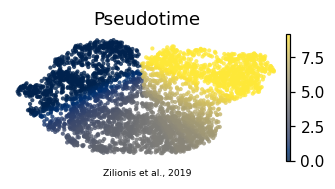

In [ ]:
# save manifold (sanitize non-serializable ElPiGraph uns entry)
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
# DELIVERABLE manifold.pdf -- pseudotime on the oriented house layout
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')
fig